# Lab Assignment 8 – NLP on Health-Related Headlines: Cleaning, Exploration & LDA Topic Modelling
**Course:** CSET343 – AI in Healthcare | **B.Tech, 4th Year, Sem VII**

**Objective:** Process real-world healthcare text with NLP and use **topic modelling** to discover what public-health news is about.
**Dataset:** *Health-Related Headlines Datasets for NLP* (Wuraola Oyewusi, GitHub) – health headlines, titles and teasers from news sources, journals and web articles.

| Task | Content |
|---|---|
| 1 | Load → lowercase, punctuation removal, tokenisation, stop-word removal, lemmatisation → show cleaned samples |
| 2 | Word-frequency distribution, word cloud, top-20 words bar plot |
| 3 | LDA topic model (gensim): choose #topics by coherence, top-5 words per topic, **pyLDAvis** visualisation |

## 0. Setup

In [1]:
# Run once if needed:
# !pip install -q pandas numpy matplotlib seaborn nltk wordcloud gensim pyLDAvis requests openpyxl

import re, io, json, string, warnings, urllib.parse
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import requests

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 120)

## Task 1: Data Preprocessing and Cleaning
### 1.1 Load the dataset (CSV / JSON)
The cell lists every data file in the GitHub repo through the GitHub API and loads one of them (by default the largest file whose name contains "headline", otherwise the largest file).
* To pick a specific file set `FILE_NAME` (a substring of the file name); to merge all files set `COMBINE_ALL_FILES = True`.
* **Offline?** Download the repo/CSV manually and set `LOCAL_PATH` (a `.csv` / `.json` file).

In [2]:
OWNER = "WuraolaOyewusi"
REPO  = "Health-Related-Headlines-Datasets-forNatural-Language-Processing"

LOCAL_PATH = "Health_Related_Headlines_Dataset.csv"          # e.g. r"C:\data\health_headlines.csv"           # e.g. "2020" -> picks a file whose path contains this text
COMBINE_ALL_FILES = False  # True -> concatenate the text of all data files
MAX_DOCS = 30000           # cap on documents (keeps LDA fast); None = use everything

def read_bytes(b, name):
    name = name.lower()
    if name.endswith(".json"):
        for kw in ({}, {"lines": True}):
            try: return pd.read_json(io.BytesIO(b), **kw)
            except Exception: pass
        raise ValueError("Could not parse JSON: " + name)
    if name.endswith((".xlsx", ".xls")):
        return pd.read_excel(io.BytesIO(b))
    sep = "\t" if name.endswith(".tsv") else None
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try: return pd.read_csv(io.BytesIO(b), encoding=enc, sep=sep, engine="python", on_bad_lines="skip")
        except Exception: continue
    raise ValueError("Could not parse: " + name)

def fetch_repo_files():
    for branch in ("main", "master"):
        r = requests.get(f"https://api.github.com/repos/{OWNER}/{REPO}/git/trees/{branch}?recursive=1", timeout=60)
        if r.ok:
            blobs = [t for t in r.json()["tree"] if t["type"] == "blob" and t["path"].lower().endswith((".csv", ".json", ".tsv", ".xlsx"))]
            return branch, blobs
    raise RuntimeError("GitHub API request failed (offline or rate-limited). Download the data manually and set LOCAL_PATH.")

def download(branch, path):
    url = f"https://raw.githubusercontent.com/{OWNER}/{REPO}/{branch}/{urllib.parse.quote(path)}"
    r = requests.get(url, timeout=120); r.raise_for_status(); return r.content

if LOCAL_PATH:
    raw_frames = {LOCAL_PATH: read_bytes(open(LOCAL_PATH, "rb").read(), LOCAL_PATH)}
else:
    branch, files = fetch_repo_files()
    print("Data files in repository:")
    display(pd.DataFrame(files)[["path", "size"]].sort_values("size", ascending=False).reset_index(drop=True))
    if COMBINE_ALL_FILES:   chosen = files
    elif FILE_NAME:         chosen = [f for f in files if FILE_NAME.lower() in f["path"].lower()][:1]
    else:
        pref = [f for f in files if "headline" in f["path"].lower()] or files
        chosen = [max(pref, key=lambda f: f["size"])]
    raw_frames = {f["path"]: read_bytes(download(branch, f["path"]), f["path"]) for f in chosen}

for k, v in raw_frames.items():
    print(f"\n{k}: shape={v.shape}, columns={list(v.columns)}")


Health_Related_Headlines_Dataset.csv: shape=(39405, 5), columns=['Date', 'Source', 'Headlines', 'Teaser', 'Category']


In [3]:
def pick_text_column(d):
    # prefer typical names, otherwise the string column with the longest average text
    pref = ["headline", "title", "teaser", "text", "description", "summary", "content", "abstract"]
    obj = [c for c in d.columns if d[c].dtype == object]
    for p in pref:
        for c in obj:
            if p in str(c).lower(): return c
    return max(obj, key=lambda c: d[c].astype(str).str.len().mean())

parts = []
for k, d in raw_frames.items():
    col = pick_text_column(d); print(f"{k}: using text column -> '{col}'")
    parts.append(pd.DataFrame({"source_file": k, "raw_text": d[col].astype(str)}))
df = pd.concat(parts, ignore_index=True)

n0 = len(df)
df = df.replace({"raw_text": {"nan": np.nan, "None": np.nan, "": np.nan}}).dropna(subset=["raw_text"])
df = df.drop_duplicates(subset="raw_text").reset_index(drop=True)
print(f"\nRows: {n0} -> {len(df)} after removing missing / duplicate texts")
if MAX_DOCS and len(df) > MAX_DOCS:
    df = df.sample(MAX_DOCS, random_state=SEED).reset_index(drop=True); print(f"Sampled {MAX_DOCS} documents")
df.sample(8, random_state=SEED)[["raw_text"]]

Health_Related_Headlines_Dataset.csv: using text column -> 'Headlines'

Rows: 39405 -> 31174 after removing missing / duplicate texts
Sampled 30000 documents


,raw_text
2308,Increased Gonorrhea Infections in New Hampshire
22404,Dominican Republic Surgery Linked to Non-TB Mycobacteria ‏
23397,Tuberculosis: Clinical Trials and New Drug Regimens
25058,Metabolomic Analyses Predict Lung Injury After 9/11 Disaster
2664,Urinary Tract Infections: Causes and Treatment Update
8511,Inappropriate or Excessive Asthma Reliever Medication Use
5148,Opioids for Depression: Novel Treatment Tested
7790,A Different Kind of Opioid Crisis in Cancer Patients


### 1.2 Cleaning pipeline
Steps (in order): **lowercase → remove URLs/HTML/digits/punctuation → tokenise (NLTK `word_tokenize`) → stop-word removal (NLTK English + a few news-specific words) → POS-aware lemmatisation (WordNet) → drop very short tokens.**

In [4]:
STOP = set(stopwords.words("english"))
EXTRA_STOP = {"say", "says", "said", "new", "one", "two", "also", "get", "gets", "make", "makes", "via", "amp", "will", "could", "would",
              "may", "might", "let", "us", "year", "years", "day", "days", "time", "like", "need", "want", "know", "go", "going"}
STOP |= EXTRA_STOP
lemmatizer = WordNetLemmatizer()
URL_RE   = re.compile(r"https?://\S+|www\.\S+")
HTML_RE  = re.compile(r"<[^>]+>|&\w+;")
TRANS    = str.maketrans("", "", string.punctuation + "“”‘’–—…•")

def wn_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

def safe_tokenize(s):
    try: return word_tokenize(s)
    except LookupError: return s.split()

def lemmatize(tokens):
    try:
        return [lemmatizer.lemmatize(w, wn_pos(t)) for w, t in nltk.pos_tag(tokens)]
    except LookupError:                                  # tagger not available -> noun then verb
        return [lemmatizer.lemmatize(lemmatizer.lemmatize(w), "v") for w in tokens]

def clean_text(text, return_steps=False):
    s1 = text.lower()
    s2 = HTML_RE.sub(" ", URL_RE.sub(" ", s1))
    s3 = re.sub(r"\d+", " ", s2).translate(TRANS)
    toks = safe_tokenize(s3)
    toks_nostop = [t for t in toks if t.isalpha() and t not in STOP]
    lem = [t for t in lemmatize(toks_nostop) if len(t) > 2 and t not in STOP]
    return (s1, s3, toks, toks_nostop, lem) if return_steps else lem

# --- demonstrate each step on one headline ---
ex = df["raw_text"].iloc[3]
s1, s3, toks, nostop, lem = clean_text(ex, True)
print("Original            :", ex)
print("1) Lowercased       :", s1)
print("2) No punct/digits  :", s3)
print("3) Tokens           :", toks)
print("4) Stop-words gone  :", nostop)
print("5) Lemmatised       :", lem)

Original            : Who Chooses Prepaid Dental Care?
1) Lowercased       : who chooses prepaid dental care?
2) No punct/digits  : who chooses prepaid dental care
3) Tokens           : ['who', 'chooses', 'prepaid', 'dental', 'care']
4) Stop-words gone  : ['chooses', 'prepaid', 'dental', 'care']
5) Lemmatised       : ['chooses', 'prepay', 'dental', 'care']


In [5]:
df["tokens"] = df["raw_text"].apply(clean_text)
df["clean_text"] = df["tokens"].apply(" ".join)
before = len(df); df = df[df["tokens"].str.len() >= 2].reset_index(drop=True)
print(f"Dropped {before - len(df)} documents with <2 tokens after cleaning -> {len(df)} documents remain")
print(f"Avg tokens per document: {df['tokens'].str.len().mean():.1f}")

Dropped 62 documents with <2 tokens after cleaning -> 29938 documents remain
Avg tokens per document: 5.5


### 1.3 A few cleaned text samples

In [6]:
display(df.sample(10, random_state=SEED)[["raw_text", "clean_text"]].reset_index(drop=True))

,raw_text,clean_text
0,Anesthesiology Residents' OOOR Emergent Airway Management,anesthesiology resident ooor emergent airway management
1,"Contingency Management May Cut Drug Use, Hospitalization",contingency management cut drug use hospitalization
2,Current 'Legal Highs',current legal high
3,False Cancer Diagnosis Leads to Malpractice Suit; More,false cancer diagnosis lead malpractice suit
4,Measles Vaccine Refusal Helps Make 2014 a Record Year,measles vaccine refusal help record
5,Non-Antibiotic Treatments for Bacterial Diseases,nonantibiotic treatment bacterial disease
6,Limb Muscle Dysfunction After Acute Exacerbation of COPD,limb muscle dysfunction acute exacerbation copd
7,Fluticasone Furoate for Asthma in Adults and Adolescents,fluticasone furoate asthma adult adolescent
8,How to Prevent Falls Among Older Adults,prevent fall among old adult
9,Alcohol and Long-term Prognosis After a First Acute Myocardial Infarction,alcohol longterm prognosis first acute myocardial infarction


## Task 2: Exploratory Text Analysis & Word Visualisation
### 2.1 Word-frequency distribution

Total tokens: 164,787 | Vocabulary size: 16,712 | Hapax words (freq=1): 8,216


,word,count,rank
0,patient,2136,1
1,risk,1960,2
2,cancer,1928,3
3,pain,1803,4
4,drug,1564,5
5,use,1293,6
6,treatment,1095,7
7,fda,1076,8
8,vaccine,1032,9
9,disease,905,10


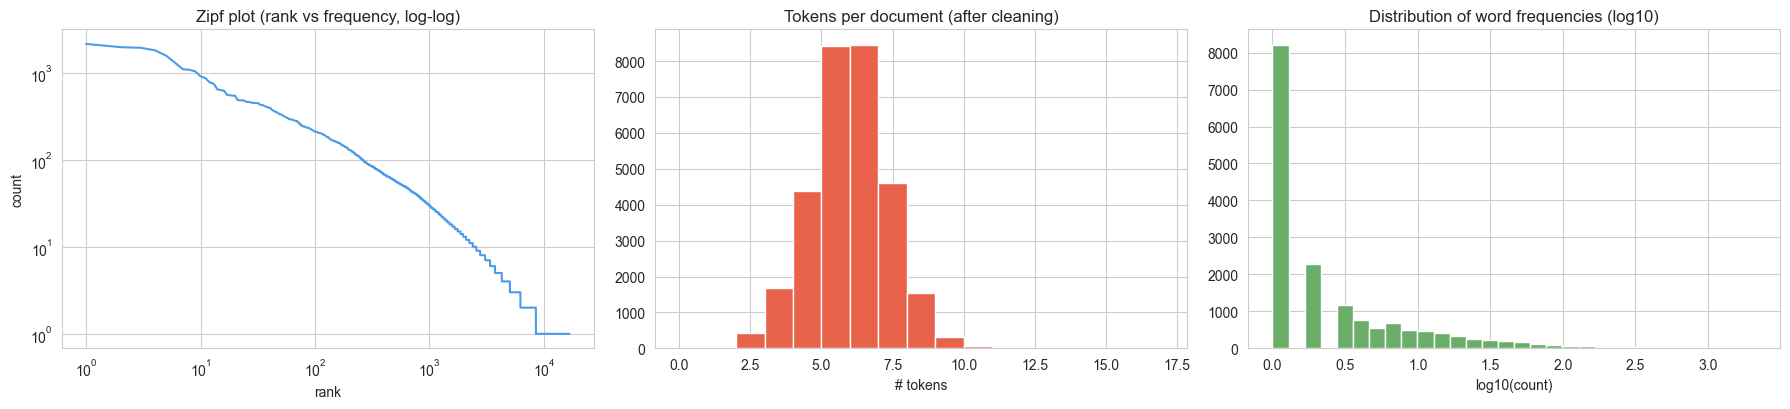

In [7]:
all_tokens = [t for toks in df["tokens"] for t in toks]
freq = Counter(all_tokens)
print(f"Total tokens: {len(all_tokens):,} | Vocabulary size: {len(freq):,} | Hapax words (freq=1): {sum(1 for v in freq.values() if v == 1):,}")
freq_df = pd.DataFrame(freq.most_common(), columns=["word", "count"]); freq_df["rank"] = np.arange(1, len(freq_df) + 1)
display(freq_df.head(20))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
ax[0].loglog(freq_df["rank"], freq_df["count"], color="#4C9BE8"); ax[0].set_title("Zipf plot (rank vs frequency, log-log)")
ax[0].set_xlabel("rank"); ax[0].set_ylabel("count")
ax[1].hist(df["tokens"].str.len(), bins=range(0, int(df["tokens"].str.len().max()) + 2), color="#E8624C", edgecolor="white")
ax[1].set_title("Tokens per document (after cleaning)"); ax[1].set_xlabel("# tokens")
ax[2].hist(np.log10(freq_df["count"]), bins=30, color="#6AAE6A", edgecolor="white")
ax[2].set_title("Distribution of word frequencies (log10)"); ax[2].set_xlabel("log10(count)")
plt.tight_layout(); plt.show()

### 2.2 Top-20 most frequent words

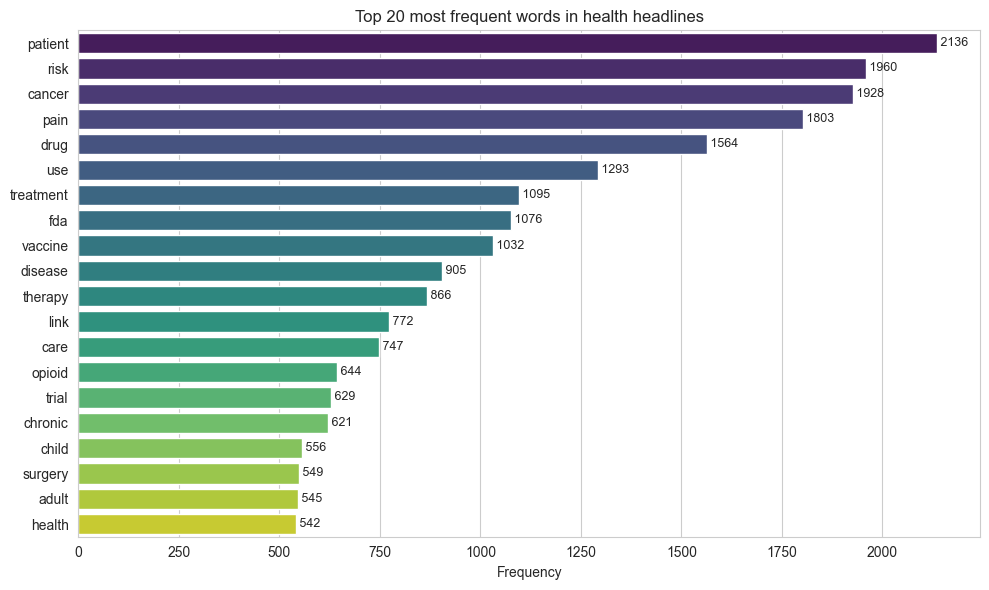

In [8]:
top20 = freq_df.head(20)
plt.figure(figsize=(10, 6))
sns.barplot(data=top20, x="count", y="word", palette="viridis")
for i, v in enumerate(top20["count"]): plt.text(v, i, f" {v}", va="center", fontsize=9)
plt.title("Top 20 most frequent words in health headlines"); plt.xlabel("Frequency"); plt.ylabel("")
plt.tight_layout(); plt.show()

### 2.3 Word cloud of the most common health-related terms

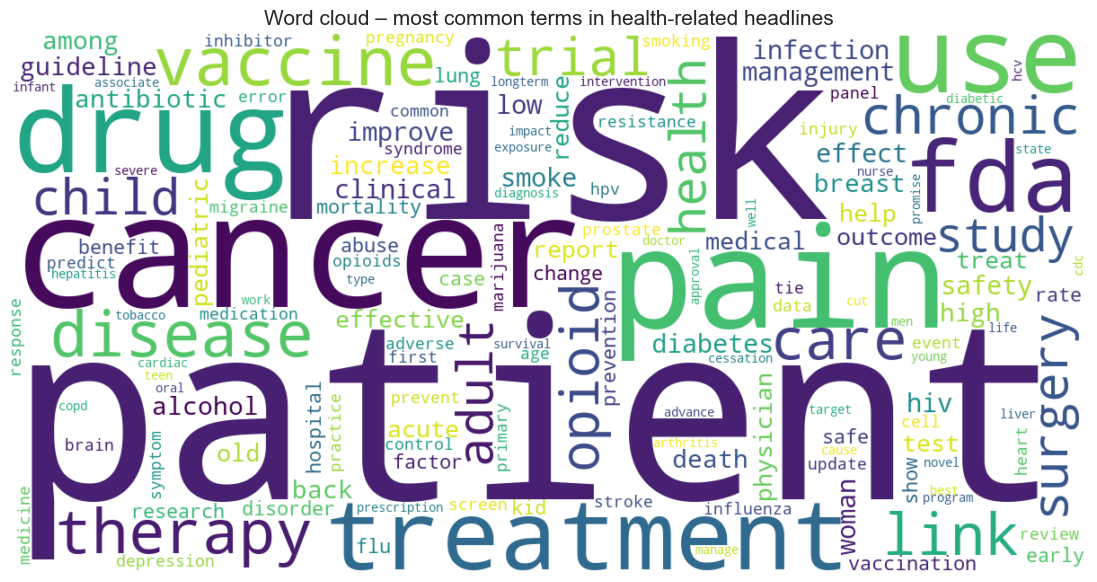

In [9]:
from wordcloud import WordCloud
wc = WordCloud(width=1200, height=600, background_color="white", colormap="viridis", max_words=150, random_state=SEED)
wc.generate_from_frequencies(dict(freq.most_common(300)))
plt.figure(figsize=(14, 7)); plt.imshow(wc, interpolation="bilinear"); plt.axis("off")
plt.title("Word cloud – most common terms in health-related headlines", fontsize=15); plt.show()

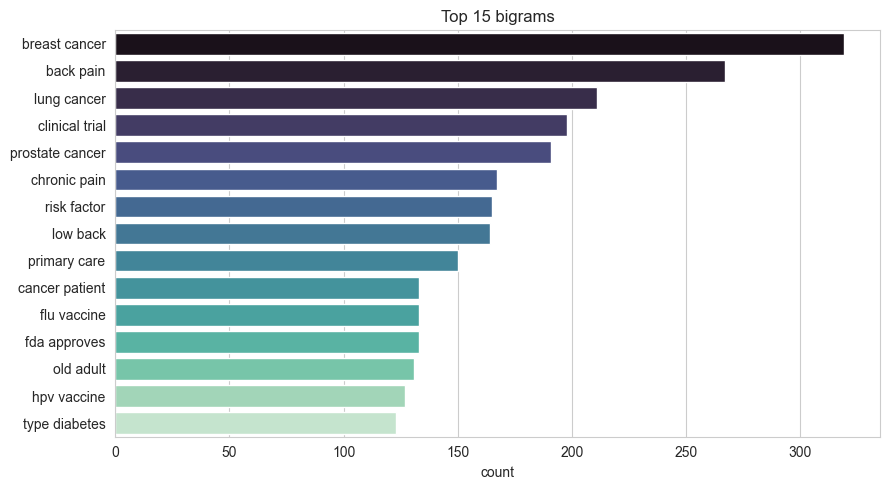

In [10]:
# Bonus: most frequent bigrams (two-word phrases) reveal context better than single words
bigrams = Counter(b for toks in df["tokens"] for b in zip(toks, toks[1:]))
bg = pd.DataFrame([(" ".join(k), v) for k, v in bigrams.most_common(15)], columns=["bigram", "count"])
plt.figure(figsize=(9, 5)); sns.barplot(data=bg, x="count", y="bigram", palette="mako")
plt.title("Top 15 bigrams"); plt.ylabel(""); plt.tight_layout(); plt.show()

## Task 3: Topic Modelling with LDA (Latent Dirichlet Allocation)
LDA assumes that every document is a **mixture of topics** and every topic is a **distribution over words**. We use gensim's `LdaModel` on a bag-of-words representation.
### 3.1 Build dictionary and corpus

In [12]:
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel

texts = df["tokens"].tolist()
dictionary = corpora.Dictionary(texts)
n_docs = len(texts)
dictionary.filter_extremes(no_below=max(3, int(0.0005 * n_docs)), no_above=0.4, keep_n=10000)   # drop very rare & very common words
corpus = [dictionary.doc2bow(t) for t in texts]
keep = [i for i, bow in enumerate(corpus) if len(bow) >= 2]                                      # drop near-empty docs
texts = [texts[i] for i in keep]; corpus = [corpus[i] for i in keep]; df = df.iloc[keep].reset_index(drop=True)
print(f"Documents: {len(corpus)} | Vocabulary after filtering: {len(dictionary)}")

Documents: 28717 | Vocabulary after filtering: 1961


### 3.2 Choose the number of topics (coherence score)
We train LDA for several values of *K* and compare the **c_v coherence** (higher = more interpretable topics). The best *K* is used for the final model.

K= 3  coherence=0.2627
K= 4  coherence=0.2492
K= 5  coherence=0.3024
K= 6  coherence=0.2827
K= 7  coherence=0.3059
K= 8  coherence=0.3022
K=10  coherence=0.3700
K=12  coherence=0.3971


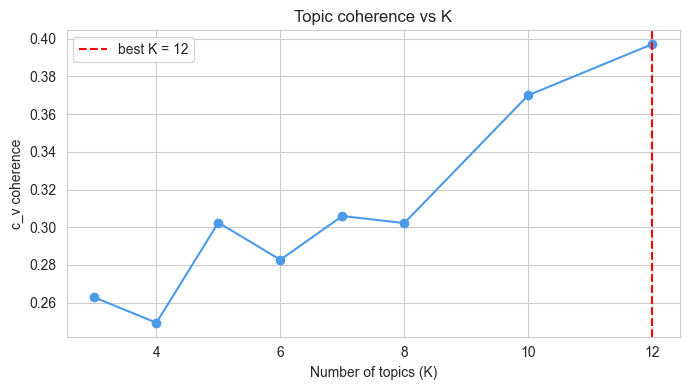

Selected model: K = 12


In [13]:
K_RANGE = [3, 4, 5, 6, 7, 8, 10, 12]
coh_rows, models = [], {}
for k in K_RANGE:
    m = LdaModel(corpus=corpus, id2word=dictionary, num_topics=k, random_state=SEED, passes=8, iterations=100,
                 chunksize=2000, alpha="auto", eta="auto")
    c = CoherenceModel(model=m, texts=texts, dictionary=dictionary, coherence="c_v", processes=1).get_coherence()
    models[k] = m; coh_rows.append({"num_topics": k, "coherence_c_v": c}); print(f"K={k:>2}  coherence={c:.4f}")

coh = pd.DataFrame(coh_rows)
BEST_K = int(coh.loc[coh["coherence_c_v"].idxmax(), "num_topics"])
plt.figure(figsize=(7, 4)); plt.plot(coh["num_topics"], coh["coherence_c_v"], "o-", color="#4C9BE8")
plt.axvline(BEST_K, color="red", ls="--", label=f"best K = {BEST_K}"); plt.legend()
plt.xlabel("Number of topics (K)"); plt.ylabel("c_v coherence"); plt.title("Topic coherence vs K"); plt.tight_layout(); plt.show()
# To force a particular number of topics, set e.g.  BEST_K = 6
lda = models[BEST_K]
print("Selected model: K =", BEST_K)

### 3.3 Dominant topics – top 5 words per topic

,Topic,Label,Top 5 words,Weights
0,0,,"care, health, low, back, primary","0.078, 0.052, 0.044, 0.044, 0.028"
1,1,,"use, vaccine, child, antibiotic, medical","0.094, 0.079, 0.042, 0.032, 0.029"
2,2,,"infection, hiv, among, effective, hospital","0.049, 0.046, 0.042, 0.032, 0.032"
3,3,,"treatment, smoke, medicine, rate, research","0.113, 0.041, 0.030, 0.026, 0.025"
4,4,,"physician, help, vaccination, alcohol, hepatitis","0.040, 0.036, 0.031, 0.030, 0.027"
5,5,,"drug, fda, adult, surgery, old","0.134, 0.095, 0.047, 0.047, 0.030"
6,6,,"risk, link, opioid, woman, death","0.144, 0.058, 0.052, 0.035, 0.032"
7,7,,"improve, diabetes, outcome, intervention, syndrome","0.046, 0.043, 0.031, 0.023, 0.020"
8,8,,"cancer, patient, pain, therapy, chronic","0.122, 0.122, 0.099, 0.052, 0.040"
9,9,,"trial, clinical, benefit, data, screen","0.078, 0.055, 0.032, 0.030, 0.029"


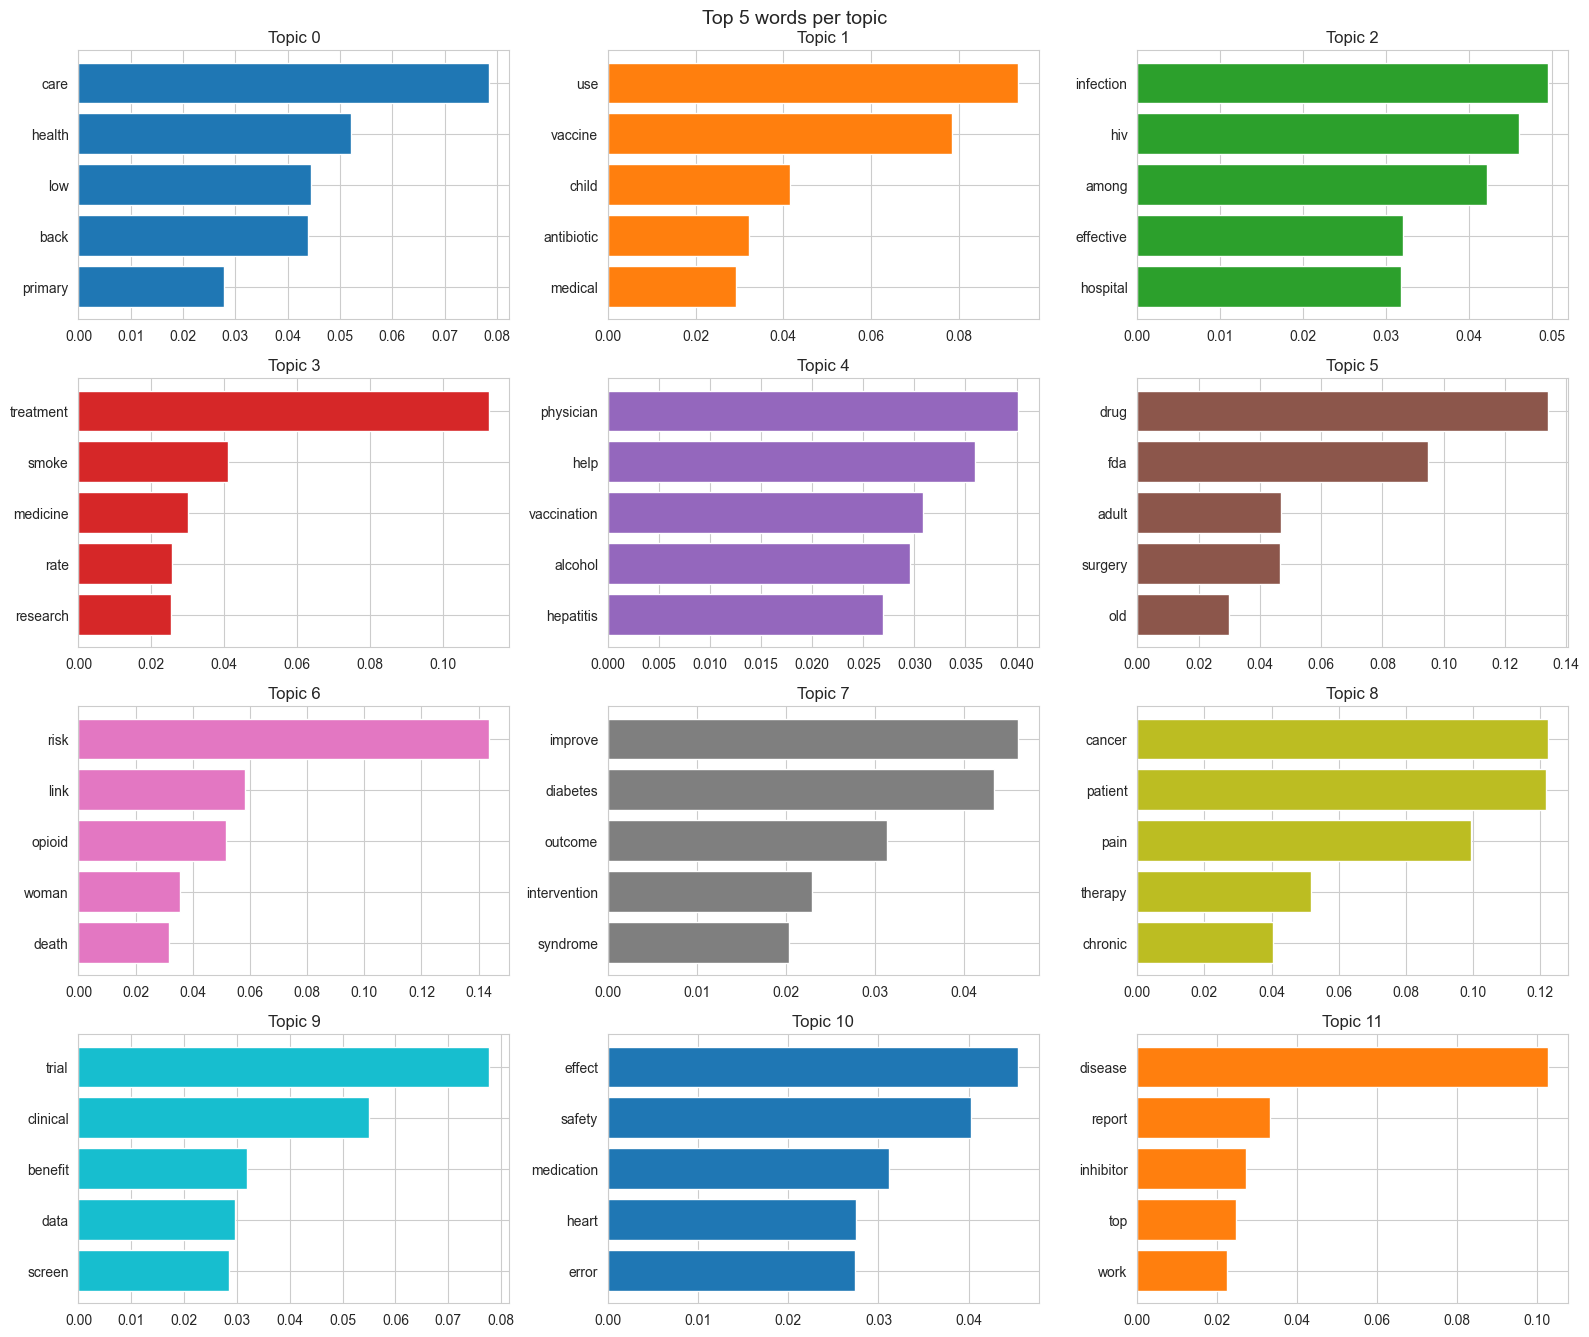

In [14]:
TOPIC_LABELS = {}     # optional: name topics yourself after reading the words, e.g. {0: "COVID-19 & vaccines", 1: "Cancer research"}

rows = []
for t in range(BEST_K):
    words = lda.show_topic(t, topn=5)
    rows.append({"Topic": t, "Label": TOPIC_LABELS.get(t, ""), "Top 5 words": ", ".join(w for w, _ in words),
                 "Weights": ", ".join(f"{p:.3f}" for _, p in words)})
topics_df = pd.DataFrame(rows); display(topics_df)

fig, axes = plt.subplots(int(np.ceil(BEST_K / 3)), 3, figsize=(16, 3.4 * int(np.ceil(BEST_K / 3))))
for t, ax in zip(range(BEST_K), np.atleast_1d(axes).ravel()):
    w, p = zip(*lda.show_topic(t, topn=5)); ax.barh(w[::-1], p[::-1], color=sns.color_palette("tab10")[t % 10]); ax.set_title(f"Topic {t}")
for ax in np.atleast_1d(axes).ravel()[BEST_K:]: ax.axis("off")
plt.suptitle("Top 5 words per topic", fontsize=14); plt.tight_layout(); plt.show()

### 3.4 Topic prevalence and representative headlines

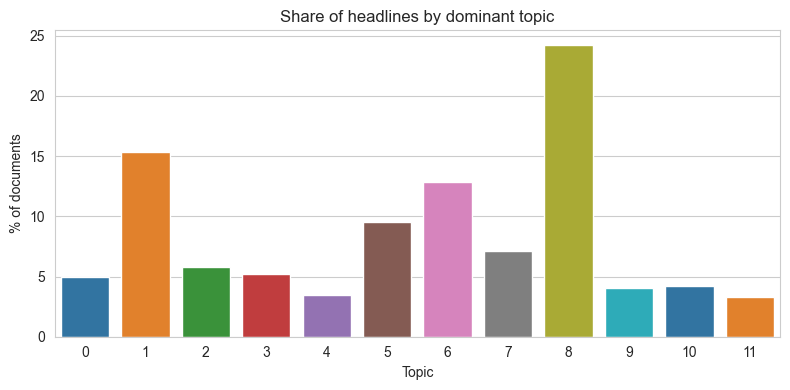


=== Topic 0: care, health, low, back, primary ===
  - Literature Commentary by Dr. John G. Bartlett: STIs, January 2008
  - Financial Sustainability: Primary Care and Mental Health
  - Ebola Spread Concentrated in Congo, Not a Wider Emergency - WHO

=== Topic 1: use, vaccine, child, antibiotic, medical ===
  - CDC: 90 New Measles Cases, Nearing Record Since Elimination
  - Hospitalists Take Charge of Antibiotic Resistance
  - The 13-Valent Pneumococcal Vaccine: Recommendations for Use in Children

=== Topic 2: infection, hiv, among, effective, hospital ===
  - Viral Infections Leave Telltale Gene Expression Signature 
  - Industry 'Youth Tobacco Prevention' More PR Than Prevention?
  - Cigarette Smoking Among Adults - United States, 2004

=== Topic 3: treatment, smoke, medicine, rate, research ===
  - Reader Poll: Is Excessive Police Force a Public Health Threat?
  - Physical Activity May Improve Teen Smoking Cessation Rates
  - Reader Poll: Ready to Answer Cannabis Questions From Pat

In [15]:
def doc_topics(bow):
    v = np.zeros(BEST_K)
    for t, p in lda.get_document_topics(bow, minimum_probability=0.0): v[t] = p
    return v

D = np.array([doc_topics(b) for b in corpus])
df["dominant_topic"] = D.argmax(1); df["topic_prob"] = D.max(1)

prev = df["dominant_topic"].value_counts(normalize=True).sort_index()
plt.figure(figsize=(8, 4)); sns.barplot(x=prev.index, y=prev.values * 100, palette="tab10")
plt.xlabel("Topic"); plt.ylabel("% of documents"); plt.title("Share of headlines by dominant topic"); plt.tight_layout(); plt.show()

for t in range(BEST_K):
    print(f"\n=== Topic {t}: {', '.join(w for w, _ in lda.show_topic(t, 5))} ===")
    for h in df[df["dominant_topic"] == t].nlargest(3, "topic_prob")["raw_text"]: print("  -", h)

### 3.5 Interactive visualisation with pyLDAvis
*Left:* each bubble is a topic (size = prevalence; distance = similarity of topics in a 2-D projection). *Right:* the most relevant terms for the selected topic – red = frequency inside the topic, blue = overall frequency. Use the λ slider to switch between frequent words (λ = 1) and topic-specific words (λ ≈ 0.3).

In [16]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

pyLDAvis.enable_notebook()
vis = gensimvis.prepare(lda, corpus, dictionary, sort_topics=False)
pyLDAvis.save_html(vis, "lda_visualization.html")      # also saved as a standalone file (open in any browser)
print("Saved: lda_visualization.html")
vis

ModuleNotFoundError: No module named 'pyLDAvis'

## Observations & Conclusion
* **Cleaning:** lowercasing, punctuation/URL/digit removal, tokenisation, stop-word removal and POS-aware lemmatisation reduce each headline to its content words (e.g. *"Vaccines are being rolled out"* → *vaccine, roll*), shrinking the vocabulary so that inflected forms (*cancers/cancer*, *trials/trial*) are counted together.
* **Frequency analysis:** the word-frequency curve follows **Zipf's law** – a few terms (health, covid, cancer, vaccine, patient, …) dominate while most words appear only once or twice. The top-20 chart and word cloud highlight the main health themes; bigrams add context (e.g. *"public health"*, *"clinical trial"*).
* **Topic model:** the number of topics was chosen by maximising c_v coherence, and each topic is a distribution of words. Reading the top-5 words (section 3.3) and the representative headlines (3.4) lets you name the topics, typically themes such as **COVID-19 / vaccines & public-health policy, cancer & disease research, mental health & wellbeing, healthcare services / hospitals / drugs, nutrition & lifestyle**. (Your exact topics depend on the file loaded and the random seed – fill in `TOPIC_LABELS` with your own names.)
* **pyLDAvis:** well-separated bubbles indicate distinct topics; overlapping bubbles suggest topics that share vocabulary and could be merged (smaller K). Large bubbles are the most prevalent public-health discussions.
* **Limitations:** headlines are very short, so topics are noisy; LDA ignores word order and context; results are sensitive to preprocessing choices, the stop-word list, K and random seed. Improvements: bigram phrases, TF-IDF filtering, longer teaser/body text, or embedding-based models such as BERTopic.